In [3]:
import pandas as pd
import numpy as np

print("Setup successful!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Setup successful!
Pandas: 3.0.6
NumPy: 2.5.3


In [5]:
import pandas as pd

df = pd.read_csv("rahul_transactions.csv")

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Dataset loaded successfully!
Rows: 1328
Columns: 8


,Date,Time,Description,Type,Amount,Balance,Mode,Ref
0,2024-01-01,03:11,AMAZON SELLER SVCS,Debit,₹2462,678275.0,UPI,TXN190872
1,01-Jan-24,05:44,BHIM-BMTC,DR,50.00,681007.0,UPI,TXN143064
2,01-Jan-24,09:35,NEFT-TECHCRUSH LABS-SALARY MAY24,CR,₹84728,484728.0,NEFT,TXN246316
3,2024-01-01,14:07,UPI-AMAN-8934@OKAXIS,Debit,₹1828,-748745.0,UPI,TXN569226
4,01 Jan 2024,14:23,BHIM-BLINKIT,Debit,270.00,680737.0,UPI,TXN968962


In [6]:
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nTRANSACTION TYPES")
print(df["Type"].value_counts())

print("\nPAYMENT MODES")
print(df["Mode"].value_counts())

DATA TYPES
Date               str
Time               str
Description        str
Type               str
Amount             str
Balance        float64
Mode               str
Ref                str
dtype: object

MISSING VALUES
Date           0
Time           0
Description    0
Type           0
Amount         0
Balance        0
Mode           0
Ref            0
dtype: int64

TRANSACTION TYPES
Type
DR       670
Debit    652
CR         6
Name: count, dtype: int64

PAYMENT MODES
Mode
UPI     1299
ATM       17
NEFT       6
IMPS       6
Name: count, dtype: int64


In [7]:
df["Amount"] = (
    df["Amount"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Amount type:", df["Amount"].dtype)
print("Date type:", df["Date"].dtype)

print("\nMissing values after cleaning:")
print(df[["Amount", "Date"]].isnull().sum())

Amount type: float64
Date type: datetime64[us]

Missing values after cleaning:
Amount    324
Date      973
dtype: int64


In [8]:
df = df.dropna(subset=["Amount", "Date"]).copy()

print("Data after cleaning:")
print("Rows:", len(df))
print("Missing Amount:", df["Amount"].isna().sum())
print("Missing Date:", df["Date"].isna().sum())

Data after cleaning:
Rows: 269
Missing Amount: 0
Missing Date: 0


In [9]:
spending_df = df[df["Type"].isin(["DR", "Debit"])].copy()

print("TOTAL ACTUAL SPENDING:", round(spending_df["Amount"].sum(), 2))
print("TOTAL SPENDING TRANSACTIONS:", len(spending_df))

TOTAL ACTUAL SPENDING: 373122.0
TOTAL SPENDING TRANSACTIONS: 268


In [10]:
spending_df["Month"] = spending_df["Date"].dt.to_period("M")

monthly_spending = spending_df.groupby("Month")["Amount"].agg(
    Transactions="count",
    Total_Spending="sum",
    Average_Spending="mean"
)

print("MONTHLY SPENDING")
print("----------------")
print(monthly_spending)

MONTHLY SPENDING
----------------
         Transactions  Total_Spending  Average_Spending
Month                                                  
2024-01            37         36382.0        983.297297
2024-02            51         69064.0       1354.196078
2024-03            40         48358.0       1208.950000
2024-04            46         71519.0       1554.760870
2024-05            54         97810.0       1811.296296
2024-06            40         49989.0       1249.725000


In [11]:
mode_spending = spending_df.groupby("Mode")["Amount"].agg(
    Transactions="count",
    Total_Spending="sum"
).sort_values("Total_Spending", ascending=False)

print("SPENDING BY PAYMENT MODE")
print("------------------------")
print(mode_spending)

SPENDING BY PAYMENT MODE
------------------------
      Transactions  Total_Spending
Mode                              
UPI            261        327122.0
IMPS             2         36000.0
ATM              5         10000.0


In [12]:
top_spending = spending_df.groupby("Description")["Amount"].sum().sort_values(
    ascending=False
).head(10)

print("TOP 10 SPENDING DESCRIPTIONS")
print("----------------------------")
print(top_spending)

TOP 10 SPENDING DESCRIPTIONS
----------------------------
Description
IMPS ZERODHA-COIN              60000.0
UPI-FLIPKART@HDFCBANK          19414.0
IMPS-RENT-LANDLORD-35126704    18000.0
IMPS-RENT-LANDLORD-49966195    18000.0
ZERODHA SECURITIES             15000.0
ZERODHA-MF SIP                 15000.0
UPI-AMAZONPAY@HDFCBANK         13674.0
UPI-MYNTRA@HDFCBANK            13185.0
POS BANGALORE RESTAURANT       12810.0
POS INDIAN OIL BANGALORE       11073.0
Name: Amount, dtype: float64


In [13]:
daily_spending = spending_df.groupby("Date")["Amount"].sum()

print("HIGHEST SPENDING DAY")
print("--------------------")
print("Date:", daily_spending.idxmax())
print("Amount: ₹", daily_spending.max())

HIGHEST SPENDING DAY
--------------------
Date: 2024-04-13 00:00:00
Amount: ₹ 22828.0


In [14]:
total_spending = spending_df["Amount"].sum()
average_spending = spending_df["Amount"].mean()
largest_spending = spending_df["Amount"].max()
top_mode = spending_df["Mode"].value_counts().idxmax()
top_month = monthly_spending["Total_Spending"].idxmax()

print("========== SPENDDNA SUMMARY ==========")
print("Total Spending        : ₹", total_spending)
print("Average Transaction   : ₹", round(average_spending, 2))
print("Largest Transaction   : ₹", largest_spending)
print("Most Used Mode        :", top_mode)
print("Highest Spending Month:", top_month)
print("Highest Spending Day  :", daily_spending.idxmax())
print("Highest Day Spending  : ₹", daily_spending.max())
print("======================================")

========== SPENDDNA SUMMARY ==========
Total Spending        : ₹ 373122.0
Average Transaction   : ₹ 1392.25
Largest Transaction   : ₹ 18000.0
Most Used Mode        : UPI
Highest Spending Month: 2024-05
Highest Spending Day  : 2024-04-13 00:00:00
Highest Day Spending  : ₹ 22828.0


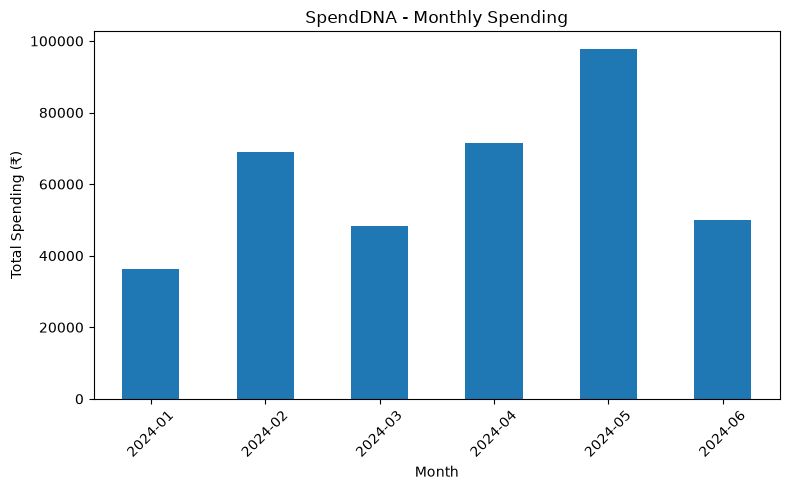

In [15]:
import matplotlib.pyplot as plt

monthly_spending["Total_Spending"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("SpendDNA - Monthly Spending")
plt.xlabel("Month")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

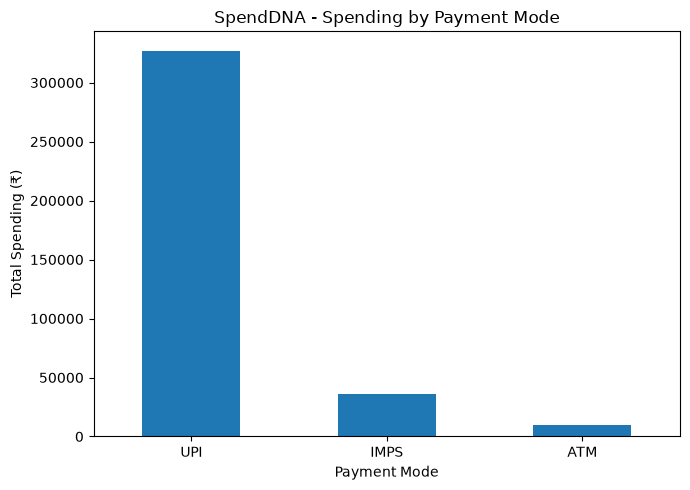

In [16]:
mode_spending["Total_Spending"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("SpendDNA - Spending by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
top_spending = spending_df.groupby("Description")["Amount"].sum().sort_values(
    ascending=False
).head(10)

print("TOP 10 SPENDING DESCRIPTIONS")
print("----------------------------")
print(top_spending)

TOP 10 SPENDING DESCRIPTIONS
----------------------------
Description
IMPS ZERODHA-COIN              60000.0
UPI-FLIPKART@HDFCBANK          19414.0
IMPS-RENT-LANDLORD-35126704    18000.0
IMPS-RENT-LANDLORD-49966195    18000.0
ZERODHA SECURITIES             15000.0
ZERODHA-MF SIP                 15000.0
UPI-AMAZONPAY@HDFCBANK         13674.0
UPI-MYNTRA@HDFCBANK            13185.0
POS BANGALORE RESTAURANT       12810.0
POS INDIAN OIL BANGALORE       11073.0
Name: Amount, dtype: float64


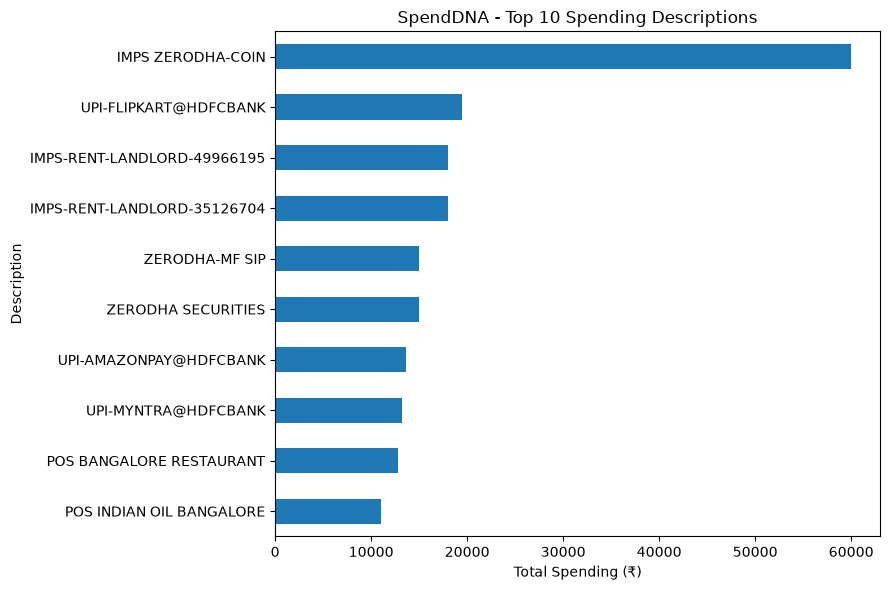

In [17]:
top_spending.sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("SpendDNA - Top 10 Spending Descriptions")
plt.xlabel("Total Spending (₹)")
plt.ylabel("Description")
plt.tight_layout()
plt.show()

In [16]:
# Final SpendDNA summary

total_spending = spending_df["Amount"].sum()
average_spending = spending_df["Amount"].mean()
largest_spending = spending_df["Amount"].max()
top_mode = spending_df["Mode"].value_counts().idxmax()
top_month = monthly_spending["Total_Spending"].idxmax()

print("========== SPENDDNA SUMMARY ==========")
print("Total Spending       : ₹", total_spending)
print("Average Transaction  : ₹", round(average_spending, 2))
print("Largest Transaction  : ₹", largest_spending)
print("Most Used Mode       :", top_mode)
print("Highest Spending Month:", top_month)
print("Highest Spending Day :", daily_spending.idxmax())
print("Highest Day Spending : ₹", daily_spending.max())
print("======================================")

========== SPENDDNA SUMMARY ==========
Total Spending       : ₹ 373122.0
Average Transaction  : ₹ 1392.25
Largest Transaction  : ₹ 18000.0
Most Used Mode       : UPI
Highest Spending Month: 2024-05
Highest Spending Day : 2024-04-13 00:00:00
Highest Day Spending : ₹ 22828.0


In [18]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 3.0 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.3 MB 3.6 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 3.9 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.3 MB 4.5 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 4.9 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.3 MB 5.0 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.3 MB 5.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 5.8 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   --------------------------------- ------ 2.1/2.5 MB 10.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 8.2 M


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
